/home/links/mf671/miniconda3/envs/falwa_env/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


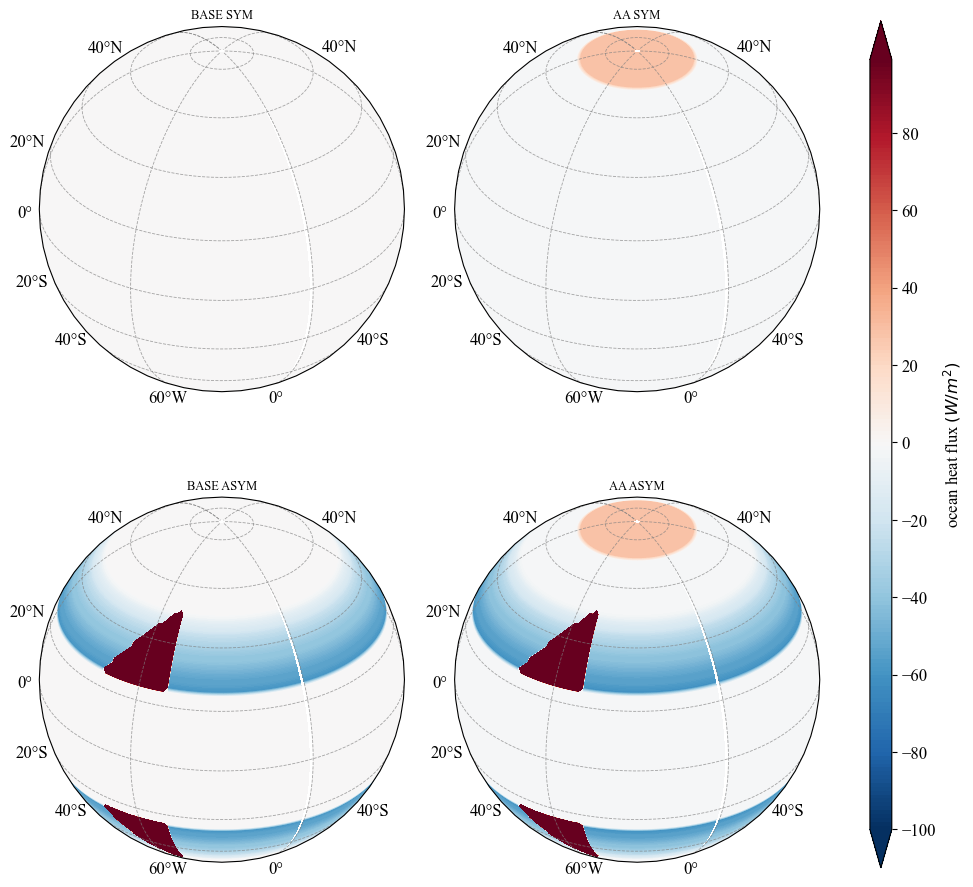

In [1]:
# python
import os
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# change to input dir
os.chdir(os.path.expanduser('~/Isca/exp/exeter_project_mf/input/'))

# Set global font family and size
plt.rcParams['font.family'] = 'Times New Roman'      # e.g., 'serif', 'sans-serif', 'monospace'
plt.rcParams['font.size'] = 12             # default font size

# source files (available in dir)
files = [
    'qflux_30_72,90_tri.nc',
    'ocean_qflux_anom_30_72,90.nc',
    'qflux_1tri_heat2.nc'
]

def get_var_and_coords(ds):
    data_var = list(ds.data_vars)[0]
    data = ds[data_var]
    lat_names = ['lat', 'latitude', 'y', 'nav_lat']
    lon_names = ['lon', 'longitude', 'x', 'nav_lon']
    lat = lon = None
    for n in lat_names:
        if n in ds.coords:
            lat = ds.coords[n].values
            break
    for n in lon_names:
        if n in ds.coords:
            lon = ds.coords[n].values
            break
    if lat is None or lon is None:
        dims = list(data.dims)
        if len(dims) >= 2:
            if lat is None and dims[-2] in ds.coords:
                lat = ds.coords[dims[-2]].values
            if lon is None and dims[-1] in ds.coords:
                lon = ds.coords[dims[-1]].values
    arr = np.asarray(data.values)
    arr = np.squeeze(arr)
    if arr.ndim > 2:
        arr = arr.reshape(arr.shape[0], -1) if arr.shape[0] == 1 else arr[0]
    return arr, lat, lon, data_var

# load all available files into a dict
loaded = {}
for fname in files:
    if not os.path.exists(fname):
        continue
    ds = xr.open_dataset(fname)
    try:
        arr, lat_vals, lon_vals, varname = get_var_and_coords(ds)
    finally:
        ds.close()
    loaded[fname] = {'arr': arr, 'lat': lat_vals, 'lon': lon_vals, 'var': varname}

if not loaded:
    raise FileNotFoundError("No input files found in directory.")

# build ordered list according to user request:
# desired order: zero field, ocean_qflux_anom_30_71,90, qflux_1tri_heat2, qflux_30_72,90_tri.nc
order_spec = [
    'zero',                    # create zero field
    'ocean_qflux_anom',        # match by substring
    'qflux_1tri',              # match by substring
    'qflux_30_72,90_tri.nc'    # exact preferred; fallback to substring 'qflux_30'
]

fields = []
titles = []
# pick a reference lat/lon from any loaded file
ref = next(iter(loaded.values()))
lat = ref['lat']
lon = ref['lon']

# zero field first (shape like first loaded array)
first_arr = ref['arr']
zero_field = np.zeros_like(first_arr)
fields.append(zero_field)
titles.append('zero field')

# helper to find loaded key by substring or exact match
def find_key(sub):
    # exact match first
    if sub in loaded:
        return sub
    # substring search
    for k in loaded:
        if sub in k:
            return k
    # fallback: try substring split without punctuation
    for k in loaded:
        if sub.replace(',', '') in k.replace(',', ''):
            return k
    return None

# add the remaining in requested order (skip 'zero' which already added)
for spec in order_spec[1:]:
    k = find_key(spec)
    if k is None:
        print(f"warning: no file matched spec '{spec}' -> skipping")
        continue
    entry = loaded[k]
    arr = entry['arr']
    # ensure lat/lon set from first matched if not already
    if lat is None and entry['lat'] is not None:
        lat = entry['lat']
    if lon is None and entry['lon'] is not None:
        lon = entry['lon']
    fields.append(arr)

# if we ended up with fewer than 4 panels, that's fine; ensure exactly 4 axs by filling with zeros
while len(fields) < 4:
    fields.append(np.zeros_like(first_arr))

titles = ['BASE SYM',
          'AA SYM',
          'BASE ASYM',
          'AA ASYM']

# compute symmetric color limits across all fields
valid_min = np.nanmin([np.nanmin(f) for f in fields])
valid_max = np.nanmax([np.nanmax(f) for f in fields])
vmax = max(abs(valid_min), abs(valid_max))
levels = np.arange(-100,100,1)
cmap = 'RdBu_r'

# figure with GridSpec: 2 rows x 3 cols, last narrow col for colorbar
fig = plt.figure(figsize=(11, 11))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.06], wspace=0.2, hspace=0.25)

proj = ccrs.Orthographic(central_longitude=-30.0, central_latitude=30.0)

# create 4 map axes (2x2)
axs = [
    fig.add_subplot(gs[0, 0], projection=proj),
    fig.add_subplot(gs[0, 1], projection=proj),
    fig.add_subplot(gs[1, 0], projection=proj),
    fig.add_subplot(gs[1, 1], projection=proj),
]

# axis for vertical colorbar (no projection)
cax = fig.add_subplot(gs[:, 2])

first_cf = None
for ax, field, ttl in zip(axs, fields, titles):
    cf = ax.contourf(lon, lat, field, levels=levels, cmap=cmap,
                     transform=ccrs.PlateCarree(), extend='both')
    if first_cf is None:
        first_cf = cf
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                      linewidth=0.6, color='gray', alpha=0.7, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    ax.set_title(ttl, fontsize=9)

fig.colorbar(first_cf, cax=cax, orientation='vertical', label='ocean heat flux $(W/m^2)$',aspect = 60)
plt.show()